# 05 v2 · Hypnodensity–feature correlations

Este notebook usa el análisis pooled como análisis principal: todas las épocas y todos los electrodos monoelectrodo disponibles se analizan conjuntamente. Los análisis por electrodo y por segmento se conservan únicamente como análisis de sensibilidad numérico, para comprobar si la relación entre las probabilidades inferidas por GSSC y los features depende del canal o de la etapa del registro.

Se incluyen únicamente GSSC, las probabilidades de W/N1/R y la entropía normalizada. Se excluyen todos los features de YASA; el conjunto queda restringido a bandpower, Catch22 y SpecParam.

## i) Imports, parámetros y estilo gráfico

Se reciclan las funciones de ensamblado, unión, correlación y exportación del proyecto. Las figuras se exportan en PNG, SVG y PDF, con la configuración tipográfica Liberation Sans usada en el notebook 02. No se usan suptitles.

In [20]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os
from IPython.display import Markdown, display
from dmt_hypnodensities import (
    add_hypnodensity_entropy, assemble_outputs, feature_value_columns,
    join_epoch_features_hypnodensities, save_figure, save_table,
    stage_feature_effect_correlations,
)

sns.reset_defaults()
system_name = os.name
standard_font = 'Liberation Sans' if system_name == 'posix' else 'Arial'
plt.rcParams.update({
    'font.family': standard_font, 'font.sans-serif': [standard_font], 'font.size': 14,
    'axes.titlesize': 14, 'axes.labelsize': 13, 'xtick.labelsize': 10,
    'ytick.labelsize': 10, 'legend.fontsize': 11, 'svg.fonttype': 'none',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})
RUN_NAME = 'gap_sensitivity_000s_gssc_yasa_sleepfm_cpu_v1'
RESULTS_NAME = 'feature_hypnodensity_correlations_000s_gssc_v2'
STAGER = 'gssc'
STAGES = ('W', 'N1', 'R', 'entropy')
RESPONSE_COLUMNS = ('prob_W', 'prob_N1', 'prob_R', 'entropy')
PHASES, DOSES = ('before', 'after'), ('placebo', 'DMT')
CORRELATION_METHOD, MIN_OBSERVATIONS, TOP_N = 'spearman', 30, 10

# Paths mirror 02_hypnodensity_analysis.ipynb / 06_figure2.ipynb: persisted recordings are read
# from the repo-local outputs/ directory. configs/analysis.yaml's data.output_dir points to a
# separate external folder used by the batch runner, not by these analysis notebooks.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'outputs').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
OUTPUT_ROOT = PROJECT_ROOT / 'outputs'
RUN_ROOT = OUTPUT_ROOT / RUN_NAME
TABLES_DIR = OUTPUT_ROOT / RESULTS_NAME / 'tables'
FIGURES_DIR = OUTPUT_ROOT / RESULTS_NAME / 'figures'
TABLES_DIR.mkdir(parents=True, exist_ok=True); FIGURES_DIR.mkdir(parents=True, exist_ok=True)
tables = assemble_outputs(RUN_ROOT / 'recordings', strict=True)
display({'run': RUN_NAME, 'n_feature_rows': len(tables.features), 'n_hypnodensity_rows': len(tables.hypnodensities)})

{'run': 'gap_sensitivity_000s_gssc_yasa_sleepfm_cpu_v1',
 'n_feature_rows': 54496,
 'n_hypnodensity_rows': 143456}

## ii) Selección de features y categorías Catch22

Las categorías de Catch22 se consolidan en Distribution, Autocorrelation, Symbolic, Self Affine y Other. Autocorrelation incluye las variantes lineal y no lineal. Other incluye extreme timing, simple forecasting, incremental differences y embedding_dist. Bandpower y SpecParam se mantienen como categorías propias.

In [21]:
CATCH22_CATEGORIES = {
    'c22_DN_HistogramMode_5':'Distribution', 'c22_DN_HistogramMode_10':'Distribution',
    'c22_DN_OutlierInclude_p_001_mdrmd':'Other', 'c22_DN_OutlierInclude_n_001_mdrmd':'Other',
    'c22_CO_f1ecac':'Autocorrelation', 'c22_CO_FirstMin_ac':'Autocorrelation',
    'c22_SP_Summaries_welch_rect_area_5_1':'Autocorrelation', 'c22_SP_Summaries_welch_rect_centroid':'Autocorrelation',
    'c22_FC_LocalSimple_mean3_stderr':'Other', 'c22_FC_LocalSimple_mean1_tauresrat':'Other',
    'c22_MD_hrv_classic_pnn40':'Other', 'c22_SB_BinaryStats_mean_longstretch1':'Symbolic',
    'c22_SB_BinaryStats_diff_longstretch0':'Symbolic', 'c22_SB_MotifThree_quantile_hh':'Symbolic',
    'c22_SB_TransitionMatrix_3ac_sumdiagcov':'Symbolic', 'c22_CO_HistogramAMI_even_2_5':'Autocorrelation',
    'c22_CO_trev_1_num':'Autocorrelation', 'c22_IN_AutoMutualInfoStats_40_gaussian_fmmi':'Autocorrelation',
    'c22_PD_PeriodicityWang_th0_01':'Autocorrelation', 'c22_CO_Embed2_Dist_tau_d_expfit_meandiff':'Other',
    'c22_SC_FluctAnal_2_rsrangefit_50_1_logi_prop_r1':'Self Affine',
    'c22_SC_FluctAnal_2_dfa_50_1_2_logi_prop_r1':'Self Affine',
}
CATCH22_SHORT_NAMES = {
    'c22_DN_HistogramMode_5':'mode_5', 'c22_DN_HistogramMode_10':'mode_10',
    'c22_DN_OutlierInclude_p_001_mdrmd':'outlier_timing_pos', 'c22_DN_OutlierInclude_n_001_mdrmd':'outlier_timing_neg',
    'c22_CO_f1ecac':'acf_timescale', 'c22_CO_FirstMin_ac':'acf_first_min',
    'c22_SP_Summaries_welch_rect_area_5_1':'low_freq_power', 'c22_SP_Summaries_welch_rect_centroid':'centroid_freq',
    'c22_FC_LocalSimple_mean3_stderr':'forecast_error', 'c22_FC_LocalSimple_mean1_tauresrat':'whiten_timescale',
    'c22_MD_hrv_classic_pnn40':'high_fluctuation', 'c22_SB_BinaryStats_mean_longstretch1':'stretch_high',
    'c22_SB_BinaryStats_diff_longstretch0':'stretch_decreasing', 'c22_SB_MotifThree_quantile_hh':'entropy_pairs',
    'c22_CO_HistogramAMI_even_2_5':'ami2', 'c22_CO_trev_1_num':'trev',
    'c22_IN_AutoMutualInfoStats_40_gaussian_fmmi':'ami_timescale', 'c22_SB_TransitionMatrix_3ac_sumdiagcov':'transition_variance',
    'c22_PD_PeriodicityWang_th0_01':'periodicity', 'c22_CO_Embed2_Dist_tau_d_expfit_meandiff':'embedding_dist',
    'c22_SC_FluctAnal_2_rsrangefit_50_1_logi_prop_r1':'rs_range', 'c22_SC_FluctAnal_2_dfa_50_1_2_logi_prop_r1':'dfa',
}
CATEGORY_COLORS = {'Bandpower':"#E7B6E6", 'Distribution':"#F7B99B", 'Autocorrelation':'#6DD3CE', 'Symbolic':"#8FB339", 'Self Affine':"#DF5489", 'Other':"#8D7F70", 'SpecParam':"#678E97"}
def feature_category(feature):
    if feature.startswith('bp_'): return 'Bandpower'
    if feature.startswith('specparam_'): return 'SpecParam'
    category = CATCH22_CATEGORIES.get(feature)
    if category in {'Distribution','Autocorrelation','Symbolic','Self Affine','Other'}: return category
    raise KeyError(f'Feature without category: {feature}')
ALL_FEATURES = feature_value_columns(tables.features)
FEATURES = tuple(f for f in ALL_FEATURES if f.startswith(('bp_', 'c22_', 'specparam_')))
FEATURE_CATEGORY = {f: feature_category(f) for f in FEATURES}
missing = sorted(f for f in FEATURES if f.startswith('c22_') and f not in CATCH22_CATEGORIES)
if missing: raise KeyError(f'Catch22 columns missing from category map: {missing}')
FEATURE_LABEL = {feature: CATCH22_SHORT_NAMES.get(feature, feature) for feature in FEATURES}
display(pd.Series(FEATURE_CATEGORY, name='category').rename_axis('feature').rename(index=FEATURE_LABEL).to_frame())


,category
feature,
bp_rel_delta,Bandpower
bp_rel_theta,Bandpower
bp_rel_alpha,Bandpower
bp_rel_sigma,Bandpower
bp_rel_beta,Bandpower
bp_rel_gamma,Bandpower
specparam_offset,SpecParam
specparam_exponent,SpecParam
specparam_r2,SpecParam


## iii) Tabla analítica a nivel de época

Se añade entropía normalizada a partir de las cinco probabilidades y se filtra GSSC. Se conservan los metadatos de electrodo, fase y condición para los tests de sensibilidad posteriores.

In [22]:
tables.hypnodensities

,recording_id,subject,session,condition,block_id,epoch,stager,channel_set,electrode,el_10-20,...,prob_R,stage,continuous_run_id,epoch_in_run,break_before,gap_before_seconds,absolute_start,absolute_end,experimental_label,channel_set_10-20
0,DMTCI_P07D1_inner,P07,D1,placebo,DMTCI_P07D1_inner__B000,0,gssc,E144,E144,C2,...,0.032043,W,DMTCI_P07D1_inner__R0003,0,False,NaN,55.072,85.070,outside,C2
1,DMTCI_P07D1_inner,P07,D1,placebo,DMTCI_P07D1_inner__B000,0,gssc,E53,E53,C1,...,0.025668,W,DMTCI_P07D1_inner__R0003,0,False,NaN,55.072,85.070,outside,C1
2,DMTCI_P07D1_inner,P07,D1,placebo,DMTCI_P07D1_inner__B000,0,gssc,E8,E8,FCz,...,0.010036,N1,DMTCI_P07D1_inner__R0003,0,False,NaN,55.072,85.070,outside,FCz
3,DMTCI_P07D1_inner,P07,D1,placebo,DMTCI_P07D1_inner__B000,0,gssc,E15,E15,Fz,...,0.012816,N1,DMTCI_P07D1_inner__R0003,0,False,NaN,55.072,85.070,outside,Fz
4,DMTCI_P07D1_inner,P07,D1,placebo,DMTCI_P07D1_inner__B000,0,gssc,E197,E197,FC2,...,0.059207,W,DMTCI_P07D1_inner__R0003,0,False,NaN,55.072,85.070,outside,FC2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143451,DMTCI_P28D2_inner,P28,D2,DMT,DMTCI_P28D2_inner__B019,0,sleepfm,E129,E129,P2,...,0.144366,N2,DMTCI_P28D2_inner__R0144,0,False,NaN,2463.700,2493.698,after,P2
143452,DMTCI_P28D2_inner,P28,D2,DMT,DMTCI_P28D2_inner__B019,0,sleepfm,E116,E116,O1,...,0.120802,N2,DMTCI_P28D2_inner__R0144,0,False,NaN,2463.700,2493.698,after,O1
143453,DMTCI_P28D2_inner,P28,D2,DMT,DMTCI_P28D2_inner__B019,0,sleepfm,E119,E119,POz,...,0.149163,N2,DMTCI_P28D2_inner__R0144,0,False,NaN,2463.700,2493.698,after,POz
143454,DMTCI_P28D2_inner,P28,D2,DMT,DMTCI_P28D2_inner__B019,0,sleepfm,E115,E115,PO7,...,0.079103,N2,DMTCI_P28D2_inner__R0144,0,False,NaN,2463.700,2493.698,after,PO7


In [23]:
epoch_analysis = join_epoch_features_hypnodensities(tables.features, add_hypnodensity_entropy(tables.hypnodensities), strict=True)
epoch_analysis = epoch_analysis.loc[epoch_analysis['stager'].astype(str).eq(STAGER)].copy()
save_table(epoch_analysis, TABLES_DIR / 'epoch_feature_hypnodensity_filtered.parquet')
display(epoch_analysis.shape)


(54496, 79)

## iv) Análisis principal pooled y ranking por W

La correlación pooled usa todas las observaciones disponibles. El ranking se define exclusivamente con prob_W y se reutiliza en todos los resultados posteriores.

In [24]:
pooled_correlations = stage_feature_effect_correlations(epoch_analysis, stage_columns=RESPONSE_COLUMNS, feature_columns=FEATURES, group_by=('stager',), methods=(CORRELATION_METHOD,), min_observations=MIN_OBSERVATIONS)
pooled_correlations = pooled_correlations.loc[pooled_correlations['stager'].astype(str).eq(STAGER)].copy()
save_table(pooled_correlations, TABLES_DIR / 'pooled_feature_probability_correlations.csv')
pooled_matrix = pooled_correlations.pivot(index='stage', columns='feature', values='correlation').reindex(STAGES)
feature_order = pooled_matrix.loc['W'].sort_values(ascending=False, na_position='last').index.tolist()
ranked_matrix = pooled_matrix.loc[:, feature_order]
display(ranked_matrix.rename(columns=FEATURE_LABEL))


feature,bp_rel_alpha,whiten_timescale,centroid_freq,specparam_error,low_freq_power,stretch_decreasing,ami2,embedding_dist,trev,periodicity,...,acf_first_min,bp_rel_gamma,specparam_exponent,dfa,acf_timescale,stretch_high,bp_rel_theta,rs_range,ami_timescale,bp_rel_delta
stage,,,,,,,,,,,,,,,,,,,,,
W,0.765763,0.686684,0.570166,0.413695,0.308869,0.295017,0.270485,0.185596,0.129529,0.050446,...,-0.289592,-0.414935,-0.423518,-0.501374,-0.509270,-0.611099,-0.684192,-0.703092,-0.765633,-0.890609
N1,-0.730279,-0.660138,-0.534172,-0.399423,-0.332818,-0.318229,-0.274875,-0.209765,-0.129901,-0.073446,...,0.266318,0.442687,0.387314,0.486317,0.469733,0.568607,0.672761,0.676819,0.729153,0.850215
R,-0.732570,-0.693013,-0.514537,-0.443367,-0.418389,-0.386011,-0.312420,-0.255615,-0.151673,-0.083558,...,0.256626,0.497923,0.321830,0.506367,0.433864,0.525985,0.682700,0.699367,0.721409,0.837025
entropy,-0.742962,-0.680025,-0.532205,-0.417302,-0.348904,-0.330052,-0.297396,-0.222921,-0.130767,-0.092324,...,0.253328,0.451590,0.387163,0.509707,0.467002,0.578621,0.673793,0.691907,0.738602,0.865625


## v) Analysis 6 — Feature ranking heatmap, ordered by wakefulness correlation

El primer plot muestra las cuatro respuestas y las features ordenadas por la correlación pooled con W. El color de las etiquetas codifica la categoría del feature.

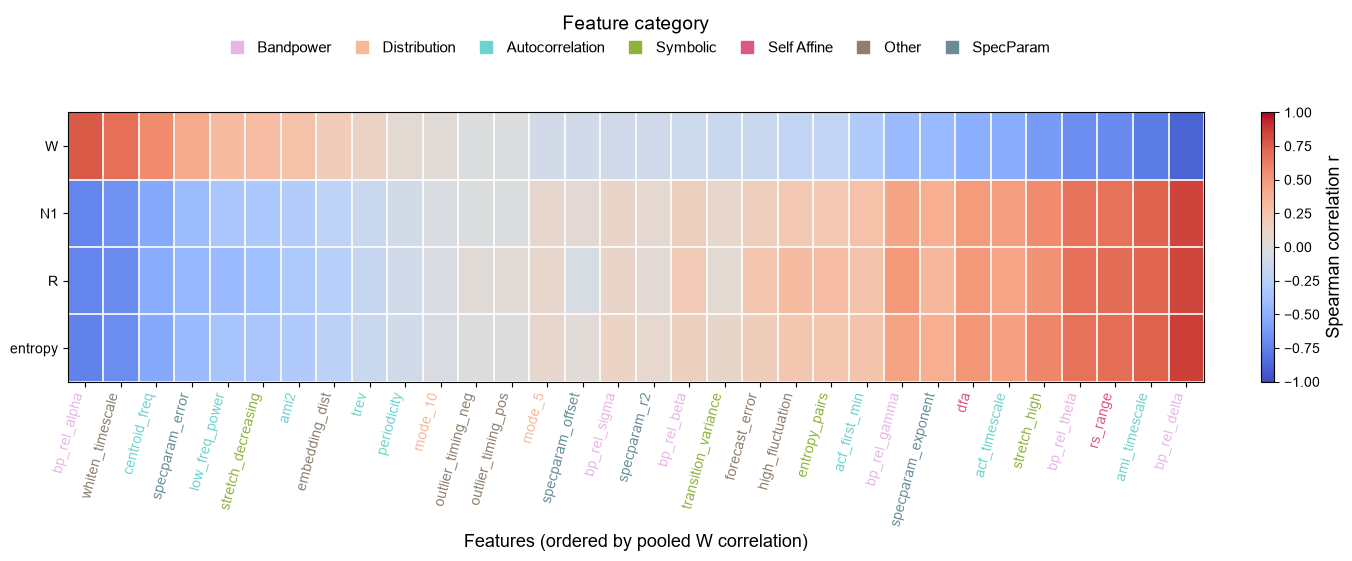

In [25]:
def category_legend(axis):
    handles = [plt.Line2D([0],[0], marker='s', linestyle='', color=c, markersize=9, label=k) for k,c in CATEGORY_COLORS.items()]
    axis.legend(handles=handles, title='Feature category', bbox_to_anchor=(0.5,1.16), loc='lower center', ncol=len(handles), frameon=False, columnspacing=1.0, handletextpad=0.35)
figure, axis = plt.subplots(figsize=(max(12, .42*len(feature_order)), 5.5), constrained_layout=True)
image = axis.imshow(ranked_matrix.to_numpy(float), vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
axis.set_xticks(np.arange(len(feature_order)), [FEATURE_LABEL[f] for f in feature_order], rotation=75, ha='right'); axis.set_yticks(np.arange(len(STAGES)), STAGES)
axis.set_xlabel('Features (ordered by pooled W correlation)'); axis.set_ylabel('')
axis.set_xticks(np.arange(-.5, len(feature_order), 1), minor=True); axis.set_yticks(np.arange(-.5, len(STAGES), 1), minor=True)
axis.grid(False, which='major'); axis.grid(which='minor', color='white', linewidth=1.2); axis.tick_params(which='minor', bottom=False, left=False)
for label, feature in zip(axis.get_xticklabels(), feature_order): label.set_color(CATEGORY_COLORS[FEATURE_CATEGORY[feature]])
figure.colorbar(image, ax=axis, label='Spearman correlation r'); category_legend(axis)
save_figure(figure, FIGURES_DIR / '01_pooled_feature_ranking_heatmap', formats=('png','svg','pdf')); plt.show()


## vi) Sensitivity analysis: electrodos y segmentos

Se repiten las correlaciones agrupando por electrodo, por fase × condición y por electrodo × fase × condición. Estos subanálisis se reportan solo numéricamente. Para cada respuesta se resume la similitud con el vector pooled mediante r entre vectores, diferencia absoluta media y diferencia absoluta máxima.

In [26]:
segment_table = epoch_analysis.loc[epoch_analysis['experimental_label'].astype(str).isin(PHASES) & epoch_analysis['condition'].astype(str).isin(DOSES)].copy()
specs = {'pooled':(epoch_analysis,('stager',)), 'electrode':(epoch_analysis,('stager','electrode')), 'segment':(segment_table,('stager','experimental_label','condition')), 'electrode × segment':(segment_table,('stager','electrode','experimental_label','condition'))}
correlation_tables = {}
for scope,(data,groups) in specs.items():
    result = stage_feature_effect_correlations(data, stage_columns=RESPONSE_COLUMNS, feature_columns=FEATURES, group_by=groups, methods=(CORRELATION_METHOD,), min_observations=MIN_OBSERVATIONS)
    result['analysis_scope'] = scope; correlation_tables[scope] = result
    save_table(result, TABLES_DIR / f'{scope.replace(" × ","_").replace(" ","_")}_correlations.csv')
pooled_lookup = pooled_correlations.set_index(['stage','feature'])['correlation']
rows = []
for scope,result in correlation_tables.items():
    for stage in STAGES:
        current = result.loc[result['stage'].eq(stage)].copy()
        if scope == 'pooled': vectors = current[['feature','correlation']].assign(group='pooled')
        else:
            group_columns = [c for c in specs[scope][1] if c != 'stager']
            vectors = current.pivot_table(index=group_columns, columns='feature', values='correlation').reset_index().melt(id_vars=group_columns, var_name='feature', value_name='correlation')
            vectors['group'] = vectors[group_columns].astype(str).agg(' | '.join, axis=1)
        vectors['pooled'] = vectors['feature'].map(lambda f: pooled_lookup.get((stage,f), np.nan)); valid = vectors.dropna(subset=['correlation','pooled'])
        rows.append({'analysis_scope':scope,'response':stage,'n_group_vectors':vectors['group'].nunique(),'n_feature_values':len(valid),'vector_r_vs_pooled':1.0 if scope=='pooled' else valid['correlation'].corr(valid['pooled']),'mean_abs_delta_r':(valid['correlation']-valid['pooled']).abs().mean(),'max_abs_delta_r':(valid['correlation']-valid['pooled']).abs().max()})
sensitivity_summary = pd.DataFrame(rows); save_table(sensitivity_summary, TABLES_DIR / 'sensitivity_summary.csv')
display(sensitivity_summary.style.format({'vector_r_vs_pooled':'{:.3f}','mean_abs_delta_r':'{:.3f}','max_abs_delta_r':'{:.3f}'}))


,analysis_scope,response,n_group_vectors,n_feature_values,vector_r_vs_pooled,mean_abs_delta_r,max_abs_delta_r
0,pooled,W,1,32,1.000,0.000,0.000
1,pooled,N1,1,32,1.000,0.000,0.000
2,pooled,R,1,32,1.000,0.000,0.000
3,pooled,entropy,1,32,1.000,0.000,0.000
4,electrode,W,32,1024,0.977,0.066,0.396
5,electrode,N1,32,1024,0.980,0.060,0.396
6,electrode,R,32,1024,0.978,0.063,0.440
7,electrode,entropy,32,1024,0.979,0.062,0.401
8,segment,W,4,128,0.963,0.082,0.516
9,segment,N1,4,128,0.968,0.071,0.515


## vii) Volcano plot de las asociaciones LME: after y late

Grilla 2×4 (fases after/late × W, N1, R, entropía) con todos los tests feature–respuesta del modelo de deltas. El eje x es el coeficiente de interacción β (sin estandarizar) y el eje y es −log10(p); las líneas discontinuas marcan los umbrales de FDR.

In [27]:
import warnings
import statsmodels.formula.api as smf

DELTA_PHASES = ('before', 'after', 'late')
delta_source = epoch_analysis.loc[
    epoch_analysis['experimental_label'].astype(str).isin(DELTA_PHASES)
    & epoch_analysis['condition'].astype(str).isin(DOSES)
].copy()
delta_means = (
    delta_source.groupby(['subject', 'condition', 'experimental_label', 'electrode'], observed=True)[
        list(RESPONSE_COLUMNS) + list(FEATURES)
    ].mean().reset_index()
)
delta_keys = ['subject', 'experimental_label', 'electrode']
dmt = delta_means.loc[delta_means['condition'].astype(str).eq('DMT')].drop(columns='condition').set_index(delta_keys)
placebo = delta_means.loc[delta_means['condition'].astype(str).eq('placebo')].drop(columns='condition').set_index(delta_keys)
common_keys = dmt.index.intersection(placebo.index)
delta_data = (dmt.loc[common_keys] - placebo.loc[common_keys]).reset_index()
delta_data['phase'] = pd.Categorical(delta_data['experimental_label'].astype(str), categories=DELTA_PHASES, ordered=True)
feature_delta_mean = delta_data[list(FEATURES)].mean()
feature_delta_sd = delta_data[list(FEATURES)].std()
delta_data[list(FEATURES)] = (delta_data[list(FEATURES)] - feature_delta_mean) / feature_delta_sd
display({
    'delta_rows': len(delta_data),
    'subjects_by_phase': delta_data.groupby('phase', observed=True)['subject'].nunique().to_dict(),
    'complete_subjects_all_phases': int(delta_data.groupby('subject')['phase'].nunique().eq(len(DELTA_PHASES)).sum()),
})

def bh_adjust(p_values):
    values = np.asarray(p_values, dtype=float)
    adjusted = np.full(values.shape, np.nan)
    finite = np.flatnonzero(np.isfinite(values))
    if finite.size:
        order = np.argsort(values[finite])
        sorted_values = values[finite][order]
        sorted_adjusted = sorted_values * finite.size / np.arange(1, finite.size + 1)
        sorted_adjusted = np.minimum.accumulate(sorted_adjusted[::-1])[::-1]
        adjusted[finite[order]] = np.minimum(sorted_adjusted, 1.0)
    return adjusted

lme_rows = []
for feature in FEATURES:
    for response in RESPONSE_COLUMNS:
        data = delta_data[['subject', 'electrode', 'phase', feature, response]].replace([np.inf, -np.inf], np.nan).dropna().rename(columns={feature: 'delta_feature', response: 'delta_response'})
        formula = 'delta_response ~ delta_feature * C(phase, Treatment(reference=\"before\"))'
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model = smf.mixedlm(formula, data=data, groups=data['subject'], vc_formula={'electrode': '0 + C(electrode)'}, re_formula='1')
            fit = model.fit(reml=False, method='lbfgs', maxiter=400, disp=False)
        confidence = fit.conf_int()
        for phase in ('after', 'late'):
            term = f'delta_feature:C(phase, Treatment(reference=\"before\"))[T.{phase}]'
            lme_rows.append({
                'feature': feature, 'response': response.removeprefix('prob_'), 'contrast': phase,
                'estimate': float(fit.params[term]), 'ci95_low': float(confidence.loc[term, 0]),
                'ci95_high': float(confidence.loc[term, 1]), 'p_value': float(fit.pvalues[term]),
                'n_subjects': int(data['subject'].nunique()), 'n_rows': int(len(data)),
            })

delta_lme_results = pd.DataFrame(lme_rows)
for contrast in ('after', 'late'):
    mask = delta_lme_results['contrast'].eq(contrast)
    delta_lme_results.loc[mask, 'q_fdr'] = bh_adjust(delta_lme_results.loc[mask, 'p_value'])
save_table(delta_lme_results, TABLES_DIR / 'delta_feature_hypnodensity_lme_results.csv')

def display_delta_table(contrast):
    subset = delta_lme_results.loc[delta_lme_results['contrast'].eq(contrast)].copy()
    subset['result'] = subset.apply(lambda row: f"β={row['estimate']:.4g}; IC95% [{row['ci95_low']:.4g}, {row['ci95_high']:.4g}]; p={row['p_value']:.3g}; q={row['q_fdr']:.3g}", axis=1)
    table = subset.pivot(index='feature', columns='response', values='result').reindex(columns=['W', 'N1', 'R', 'entropy'])
    table.columns.name = None
    save_table(table.reset_index(), TABLES_DIR / f'delta_lme_{contrast}_table.csv')
    display(table)

display(Markdown('### LME delta: after'))
display_delta_table('after')
display(Markdown('### LME delta: late'))
display_delta_table('late')


{'delta_rows': 1472,
 'subjects_by_phase': {'before': 18, 'after': 13, 'late': 15},
 'complete_subjects_all_phases': 10}

### LME delta: after

,W,N1,R,entropy
feature,,,,
bp_rel_alpha,"β=0.02128; IC95% [-0.01074, 0.05331]; p=0.193;...","β=0.01718; IC95% [-0.006998, 0.04136]; p=0.164...","β=-0.002125; IC95% [-0.006385, 0.002136]; p=0....","β=-0.04145; IC95% [-0.06837, -0.01453]; p=0.00..."
bp_rel_beta,"β=-0.06588; IC95% [-0.09396, -0.0378]; p=4.25e...","β=0.06317; IC95% [0.0426, 0.08375]; p=1.78e-09...","β=0.009379; IC95% [0.005778, 0.01298]; p=3.3e-...","β=0.1185; IC95% [0.0948, 0.1421]; p=9.55e-23; ..."
bp_rel_delta,"β=0.01261; IC95% [-0.01152, 0.03674]; p=0.306;...","β=-0.04583; IC95% [-0.06489, -0.02677]; p=2.44...","β=-0.001525; IC95% [-0.005068, 0.002019]; p=0....","β=-0.01317; IC95% [-0.03358, 0.007235]; p=0.20..."
bp_rel_gamma,"β=-0.0008742; IC95% [-0.01807, 0.01632]; p=0.9...","β=-0.000238; IC95% [-0.01276, 0.01229]; p=0.97...","β=0.003678; IC95% [0.001538, 0.005818]; p=0.00...","β=0.01622; IC95% [0.001648, 0.03079]; p=0.0291..."
bp_rel_sigma,"β=0.006452; IC95% [-0.02319, 0.0361]; p=0.67; ...","β=-4.736e-07; IC95% [-0.02183, 0.02183]; p=1; q=1","β=-0.001735; IC95% [-0.005467, 0.001998]; p=0....","β=0.04765; IC95% [0.02264, 0.07266]; p=0.00018..."
bp_rel_theta,"β=-0.0243; IC95% [-0.05217, 0.003572]; p=0.087...","β=-0.01017; IC95% [-0.03074, 0.0104]; p=0.332;...","β=-0.002878; IC95% [-0.006475, 0.0007191]; p=0...","β=-0.004842; IC95% [-0.02862, 0.01894]; p=0.69..."
c22_CO_Embed2_Dist_tau_d_expfit_meandiff,"β=-0.03972; IC95% [-0.06174, -0.01769]; p=0.00...","β=0.0153; IC95% [-0.0008857, 0.03148]; p=0.063...","β=-0.004357; IC95% [-0.007142, -0.001573]; p=0...","β=0.006847; IC95% [-0.012, 0.02569]; p=0.476; ..."
c22_CO_FirstMin_ac,"β=0.03365; IC95% [0.005781, 0.06152]; p=0.018;...","β=-0.05061; IC95% [-0.07267, -0.02855]; p=6.92...","β=-0.01324; IC95% [-0.01713, -0.009343]; p=2.7...","β=-0.1059; IC95% [-0.1306, -0.08132]; p=3.39e-..."
c22_CO_HistogramAMI_even_2_5,"β=-0.02486; IC95% [-0.04584, -0.003888]; p=0.0...","β=0.01537; IC95% [0.0001746, 0.03056]; p=0.047...","β=-0.003095; IC95% [-0.005682, -0.0005075]; p=...","β=-0.01344; IC95% [-0.03115, 0.004261]; p=0.13..."


### LME delta: late

,W,N1,R,entropy
feature,,,,
bp_rel_alpha,"β=0.1057; IC95% [0.07723, 0.1342]; p=3.53e-13;...","β=-0.02648; IC95% [-0.04801, -0.00495]; p=0.01...","β=-0.003761; IC95% [-0.007584, 6.229e-05]; p=0...","β=-0.04184; IC95% [-0.06573, -0.01796]; p=0.00..."
bp_rel_beta,"β=-0.1075; IC95% [-0.1368, -0.07825]; p=5.89e-...","β=0.08315; IC95% [0.06169, 0.1046]; p=3.15e-14...","β=0.01359; IC95% [0.009705, 0.01747]; p=6.82e-...","β=0.102; IC95% [0.0774, 0.1266]; p=4.21e-16; q..."
bp_rel_delta,"β=-0.04415; IC95% [-0.06714, -0.02116]; p=0.00...","β=-0.01733; IC95% [-0.03559, 0.0009308]; p=0.0...","β=-0.003609; IC95% [-0.006998, -0.0002199]; p=...","β=-0.02451; IC95% [-0.04383, -0.005186]; p=0.0..."
bp_rel_gamma,"β=0.06815; IC95% [0.02928, 0.107]; p=0.000589;...","β=-0.03203; IC95% [-0.06044, -0.003618]; p=0.0...","β=0.001696; IC95% [-0.003144, 0.006536]; p=0.4...","β=-0.01234; IC95% [-0.0454, 0.02073]; p=0.465;..."
bp_rel_sigma,"β=-0.0519; IC95% [-0.08103, -0.02278]; p=0.000...","β=0.01721; IC95% [-0.004143, 0.03857]; p=0.114...","β=0.001295; IC95% [-0.002362, 0.004952]; p=0.4...","β=0.04323; IC95% [0.01859, 0.06786]; p=0.00058..."
bp_rel_theta,"β=-0.1059; IC95% [-0.1317, -0.08009]; p=8.38e-...","β=0.03767; IC95% [0.01869, 0.05665]; p=0.0001;...","β=-0.0002058; IC95% [-0.003523, 0.003112]; p=0...","β=0.03433; IC95% [0.01236, 0.0563]; p=0.00219;..."
c22_CO_Embed2_Dist_tau_d_expfit_meandiff,"β=-0.0795; IC95% [-0.1011, -0.05792]; p=5.14e-...","β=0.03716; IC95% [0.02129, 0.05303]; p=4.44e-0...","β=-0.0008097; IC95% [-0.003554, 0.001934]; p=0...","β=0.03817; IC95% [0.01972, 0.05662]; p=5.04e-0..."
c22_CO_FirstMin_ac,"β=-0.01815; IC95% [-0.04583, 0.009526]; p=0.19...","β=-0.02767; IC95% [-0.04945, -0.005889]; p=0.0...","β=-0.01418; IC95% [-0.01803, -0.01034]; p=4.87...","β=-0.05616; IC95% [-0.08051, -0.03181]; p=6.15..."
c22_CO_HistogramAMI_even_2_5,"β=-0.007016; IC95% [-0.0315, 0.01747]; p=0.574...","β=0.01118; IC95% [-0.006569, 0.02892]; p=0.217...","β=-0.003132; IC95% [-0.00617, -9.516e-05]; p=0...","β=-0.004054; IC95% [-0.02483, 0.01672]; p=0.70..."


In [28]:
# Standardize each LME estimate by its response's own SD (same method as notebook 02's
# standardized LME forest plot): divide beta and its CI by SD(delta_response) within that
# contrast, so W/N1/R/entropy -- whose deltas have very different intrinsic variance -- become
# comparable on the same scale in the volcano and heatmap figures below.
response_sd_lookup = {
    (contrast, response.removeprefix('prob_')): delta_data.loc[delta_data['phase'].eq(contrast), response].dropna().std(ddof=1)
    for contrast in ('after', 'late')
    for response in RESPONSE_COLUMNS
}
delta_lme_results['response_sd'] = [
    response_sd_lookup[(row['contrast'], row['response'])] for _, row in delta_lme_results.iterrows()
]
for column in ('estimate', 'ci95_low', 'ci95_high'):
    delta_lme_results[f'{column}_std'] = delta_lme_results[column] / delta_lme_results['response_sd']
save_table(delta_lme_results, TABLES_DIR / 'delta_feature_hypnodensity_lme_results.csv')
display(
    delta_lme_results[['response', 'contrast', 'response_sd']]
    .drop_duplicates()
    .sort_values(['contrast', 'response'])
    .reset_index(drop=True)
)

,response,contrast,response_sd
0,N1,after,0.169292
1,R,after,0.031326
2,W,after,0.220112
3,entropy,after,0.190010
4,N1,late,0.111363
5,R,late,0.006758
6,W,late,0.209961
7,entropy,late,0.158391


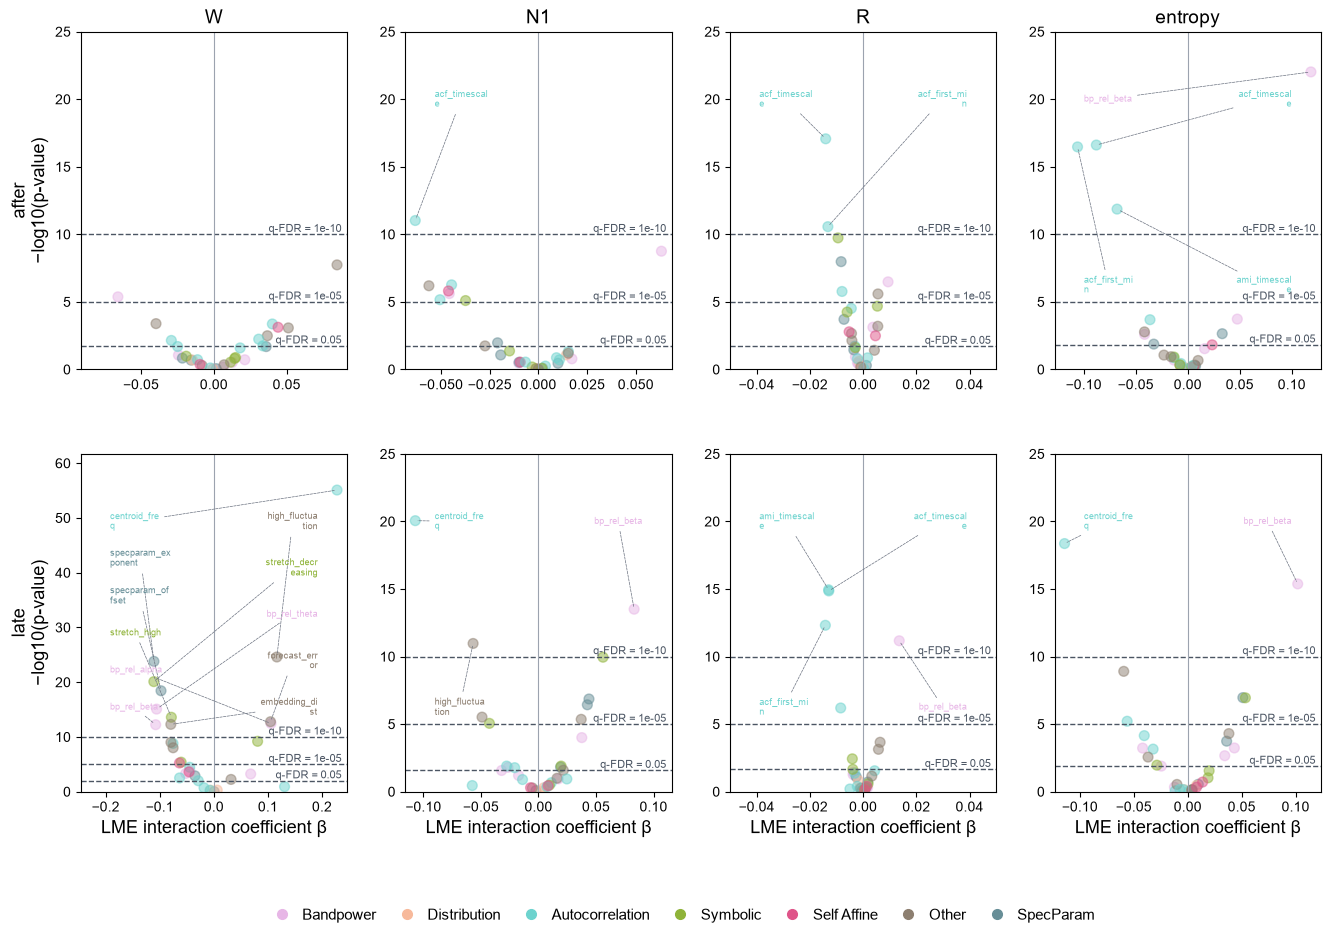

In [61]:
import textwrap
from matplotlib.lines import Line2D

target_order = ('W', 'N1', 'R', 'entropy')
contrast_order = ('after', 'late')
figure, axes = plt.subplots(2, 4, figsize=(16, 10), squeeze=False)
for row, contrast in enumerate(contrast_order):
    for col, response in enumerate(target_order):
        axis = axes[row, col]
        target = delta_lme_results.loc[
            delta_lme_results['contrast'].eq(contrast) & delta_lme_results['response'].eq(response)
        ].copy()
        target['neg_log10_p'] = -np.log10(np.clip(target['p_value'], 1e-300, None))
        axis.scatter(target['estimate'], target['neg_log10_p'],s=50, alpha=0.5,
                      color=[CATEGORY_COLORS[FEATURE_CATEGORY[f]] for f in target['feature']])
        significant = target.loc[target['q_fdr'].lt(.05)]
        if not significant.empty:
            p_threshold = significant['p_value'].max()
            y_threshold = -np.log10(p_threshold)
            axis.axhline(y_threshold, color='#4b5563', linewidth=1, linestyle='--')
            axis.text(.98, y_threshold, 'q-FDR = 0.05', transform=axis.get_yaxis_transform(),
                      ha='right', va='bottom', fontsize=8, color='#4b5563')
        x_limit = max(target['estimate'].abs().max() * 1.08, .05)
        y_limit = max(25, target['neg_log10_p'].max() * 1.12)
        axis.set_xlim(-x_limit, x_limit); axis.set_ylim(0, y_limit)
        labels = target.loc[target['neg_log10_p'].gt(10)].sort_values('neg_log10_p', ascending=False).copy()
        labels['short_feature'] = labels['feature'].map(FEATURE_LABEL)
        labels = labels.reset_index(drop=True)
        left_labels, right_labels = labels.iloc[::2], labels.iloc[1::2]
        for side, side_labels in ((-1, left_labels), (1, right_labels)):
            if side_labels.empty:
                continue
            label_y_positions = np.linspace(y_limit * .80, y_limit * .25, len(side_labels))
            for label_y, (_, label_row) in zip(label_y_positions, side_labels.iterrows()):
                axis.annotate(textwrap.fill(label_row['short_feature'], width=12),
                              xy=(label_row['estimate'], label_row['neg_log10_p']),
                              xytext=(side * x_limit * .78, label_y),
                              ha='right' if side > 0 else 'left', va='center', fontsize=6.2,
                              color=CATEGORY_COLORS[FEATURE_CATEGORY[label_row['feature']]],
                              arrowprops={'arrowstyle': '-', 'linestyle': '--', 'linewidth': .5,
                                          'color': '#6b7280', 'shrinkA': 2, 'shrinkB': 2})
        for threshold in (5, 10):
            axis.axhline(threshold, color='#4b5563', linewidth=1, linestyle='--', zorder=2)
            axis.text(.98, threshold, f'q-FDR = {10 ** (-threshold):.0e}', transform=axis.get_yaxis_transform(),
                      ha='right', va='bottom', fontsize=8, color='#4b5563')
        axis.axvline(0, color='#9ca3af', linewidth=.8)
        axis.set_title(response if row == 0 else '')
        axis.set_xlabel('LME interaction coefficient β' if row == 1 else '')
        axis.set_ylabel(f'{contrast}\n−log10(p-value)' if col == 0 else '')
        x_limit = max(target['estimate'].abs().max() * 1.08, .05)
        axis.set_xlim(-x_limit, x_limit)
        axis.set_ylim(0, y_limit)
category_handles = [Line2D([0], [0], marker='o', linestyle='', color=color, markersize=7, label=category) for category, color in CATEGORY_COLORS.items()]
figure.legend(handles=category_handles, loc='lower center', bbox_to_anchor=(.5, -.005), ncol=len(category_handles), frameon=False, columnspacing=1.0, handletextpad=.35)
figure.subplots_adjust(bottom=.14, top=.90, hspace=.25, wspace=.22)
save_figure(figure, FIGURES_DIR / '05_delta_lme_volcano_after_late_by_target', formats=('png','svg','pdf')); plt.show()


## xiii) Volcano plot de las asociaciones LME: after

Esta figura muestra únicamente la primera fila del volcano plot anterior: las asociaciones entre los cambios en los features y los cambios after en W, N1, R y entropy.

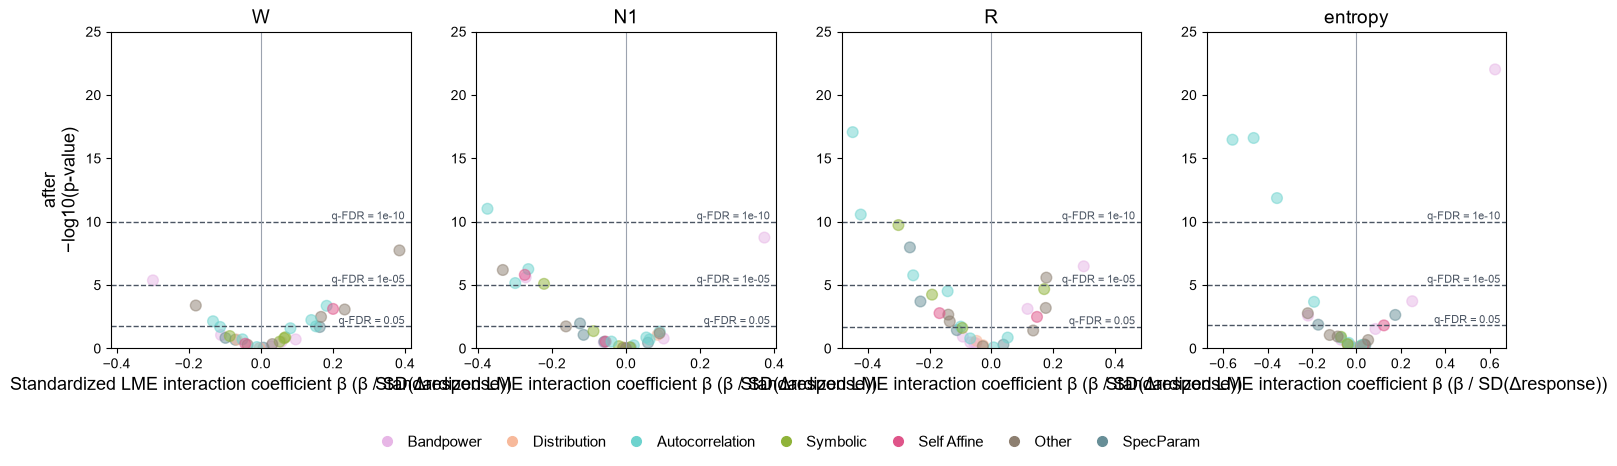

In [30]:
figure, axes = plt.subplots(1, 4, figsize=(18, 4.8), squeeze=False)
contrast = 'after'
for col, response in enumerate(target_order):
    axis = axes[0, col]
    target = delta_lme_results.loc[
        delta_lme_results['contrast'].eq(contrast) & delta_lme_results['response'].eq(response)
    ].copy()
    target['neg_log10_p'] = -np.log10(np.clip(target['p_value'], 1e-300, None))
    axis.scatter(target['estimate_std'], target['neg_log10_p'], s=60, alpha=0.5,
                 color=[CATEGORY_COLORS[FEATURE_CATEGORY[f]] for f in target['feature']])
    significant = target.loc[target['q_fdr'].lt(.05)]
    if not significant.empty:
        p_threshold = significant['p_value'].max()
        y_threshold = -np.log10(p_threshold)
        axis.axhline(y_threshold, color='#4b5563', linewidth=1, linestyle='--')
        axis.text(.98, y_threshold, 'q-FDR = 0.05', transform=axis.get_yaxis_transform(),
                  ha='right', va='bottom', fontsize=8, color='#4b5563')
    x_limit = max(target['estimate_std'].abs().max() * 1.08, .05)
    y_limit = max(25, target['neg_log10_p'].max() * 1.12)
    axis.set_xlim(-x_limit, x_limit); axis.set_ylim(0, y_limit)
    # labels = target.loc[target['neg_log10_p'].gt(10)].sort_values('neg_log10_p', ascending=False).copy()
    # labels['short_feature'] = labels['feature'].map(lambda feature: feature.split('_', 1)[1] if '_' in feature else feature)
    # labels = labels.reset_index(drop=True)
    # left_labels, right_labels = labels.iloc[::2], labels.iloc[1::2]
    # for side, side_labels in ((-1, left_labels), (1, right_labels)):
    #     if side_labels.empty:
    #         continue
    #     label_y_positions = np.linspace(y_limit * .80, y_limit * .25, len(side_labels))
    #     for label_y, (_, label_row) in zip(label_y_positions, side_labels.iterrows()):
    #         axis.annotate(textwrap.fill(label_row['short_feature'], width=12),
    #                       xy=(label_row['estimate_std'], label_row['neg_log10_p']),
    #                       xytext=(side * x_limit * .78, label_y),
    #                       ha='right' if side > 0 else 'left', va='center', fontsize=8.2,
    #                       color=CATEGORY_COLORS[FEATURE_CATEGORY[label_row['feature']]],
    #                       arrowprops={'arrowstyle': '-', 'linestyle': '--', 'linewidth': .5,
    #                                   'color': '#6b7280', 'shrinkA': 2, 'shrinkB': 2})
    for threshold in (5, 10):
        axis.axhline(threshold, color='#4b5563', linewidth=1, linestyle='--', zorder=2)
        axis.text(.98, threshold, f'q-FDR = {10 ** (-threshold):.0e}', transform=axis.get_yaxis_transform(),
                  ha='right', va='bottom', fontsize=8, color='#4b5563')
    axis.axvline(0, color='#9ca3af', linewidth=.8)
    axis.set_title(response)
    axis.set_xlabel('Standardized LME interaction coefficient β (β / SD(Δresponse))')
    axis.set_ylabel('after\n−log10(p-value)' if col == 0 else '')
category_handles = [Line2D([0], [0], marker='o', linestyle='', color=color, markersize=7, label=category) for category, color in CATEGORY_COLORS.items()]
figure.legend(handles=category_handles, loc='lower center', bbox_to_anchor=(.5, -.02), ncol=len(category_handles), frameon=False, columnspacing=1.0, handletextpad=.35)
figure.subplots_adjust(bottom=.22, top=.88, wspace=.22)
save_figure(figure, FIGURES_DIR / '05_delta_lme_volcano_after_by_target_standardized', formats=('png','svg','pdf')); plt.show()

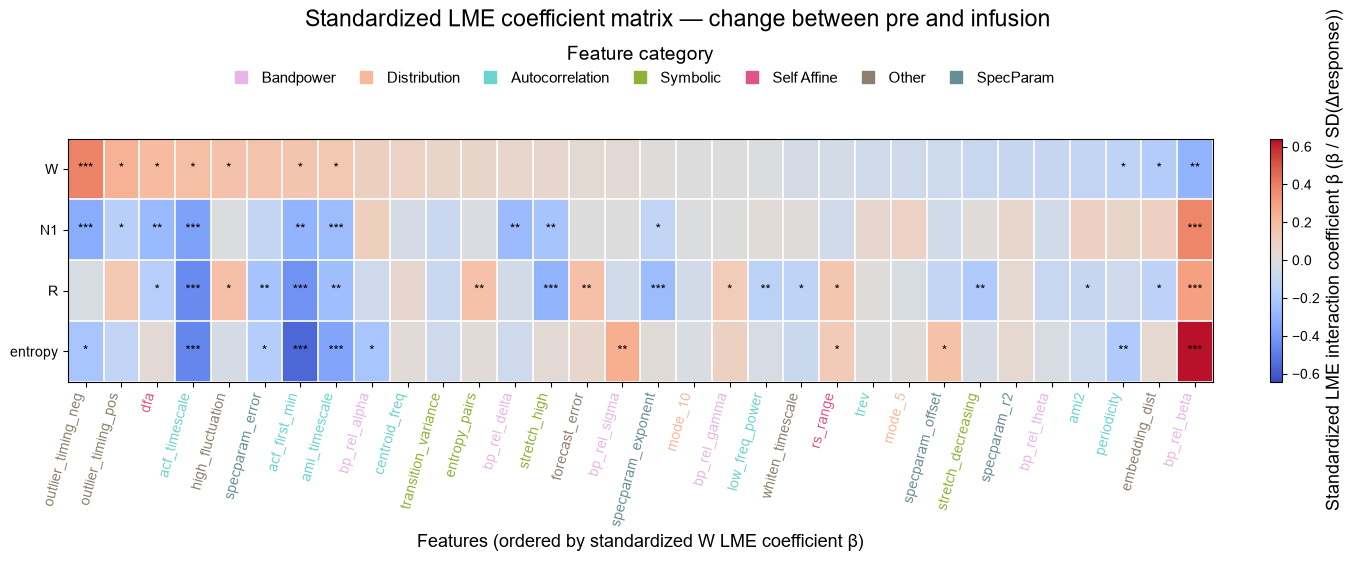

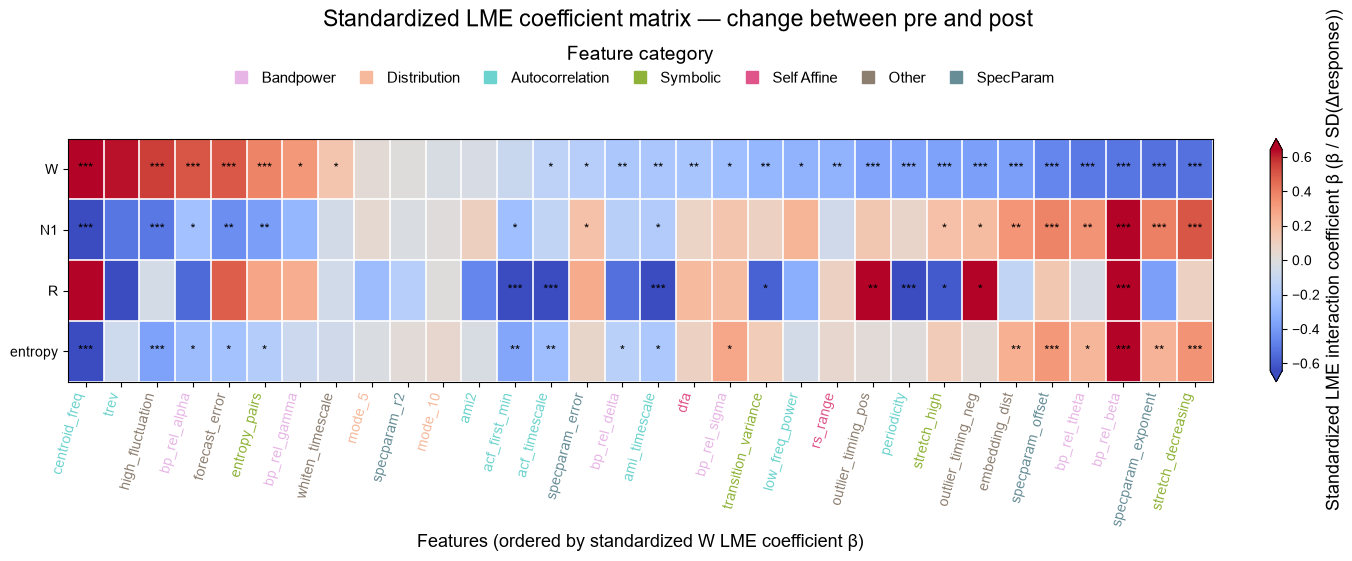

In [31]:
lme_source = delta_lme_results.copy()
lme_source['stars'] = np.select([lme_source['q_fdr'].lt(1e-5), lme_source['q_fdr'].lt(1e-3), lme_source['q_fdr'].lt(.05)], ['***', '**', '*'], default='')
# Cap the shared color scale at a robust percentile of |beta| instead of the raw max: a single
# (contrast, response, feature) outlier would otherwise saturate the axis and wash out every other
# cell's color. imshow clips values beyond vmin/vmax automatically; the colorbar's "extend" arrows
# flag that clipping happened instead of hiding it.
beta_limit = np.nanpercentile(np.abs(lme_source['estimate_std'].to_numpy(float)), 95)
# Matches the Pre / Infusion / Post phase naming used for the same contrasts in 06_figure2.ipynb.
CONTRAST_PHASE_WORD = {'after': 'infusion', 'late': 'post'}
for contrast in ('after', 'late'):
    contrast_data = lme_source.loc[lme_source['contrast'].eq(contrast)]
    feature_order = contrast_data.loc[contrast_data['response'].eq('W')].sort_values('estimate_std', ascending=False)['feature'].tolist()
    lme_matrix = contrast_data.pivot(index='response', columns='feature', values='estimate_std').reindex(index=target_order, columns=feature_order)
    lme_stars = contrast_data.pivot(index='response', columns='feature', values='stars').reindex(index=target_order, columns=feature_order).fillna('')
    figure, axis = plt.subplots(figsize=(max(12, .42 * len(feature_order)), 5.5), constrained_layout=True)
    figure.suptitle(
        f'Standardized LME coefficient matrix — change between pre and {CONTRAST_PHASE_WORD[contrast]}'
    )
    matrix_values = lme_matrix.to_numpy(float)
    image = axis.imshow(matrix_values, vmin=-beta_limit, vmax=beta_limit, cmap='coolwarm', aspect='auto')
    axis.set_xticks(np.arange(len(feature_order)), [FEATURE_LABEL[f] for f in feature_order], rotation=75, ha='right'); axis.set_yticks(np.arange(len(target_order)), target_order)
    axis.set_xlabel('Features (ordered by standardized W LME coefficient β)'); axis.set_ylabel('')
    axis.set_xticks(np.arange(-.5, len(feature_order), 1), minor=True); axis.set_yticks(np.arange(-.5, len(target_order), 1), minor=True)
    axis.grid(False, which='major'); axis.grid(which='minor', color='white', linewidth=1.2); axis.tick_params(which='minor', bottom=False, left=False)
    for label, feature in zip(axis.get_xticklabels(), feature_order): label.set_color(CATEGORY_COLORS[FEATURE_CATEGORY[feature]])
    for row, response in enumerate(target_order):
        for col, feature in enumerate(feature_order):
            axis.text(col, row, lme_stars.loc[response, feature], ha='center', va='center', color='black', fontsize=9)
    clipped_beyond = np.nanmax(np.abs(matrix_values)) > beta_limit if np.isfinite(matrix_values).any() else False
    figure.colorbar(
        image, ax=axis, label='Standardized LME interaction coefficient β (β / SD(Δresponse))',
        extend='both' if clipped_beyond else 'neither',
    )
    category_legend(axis)
    save_figure(figure, FIGURES_DIR / f'06_delta_lme_beta_matrix_{contrast}_standardized', formats=('png','svg','pdf')); plt.show()

In [32]:
# Data needed to reproduce the standardized LME coefficient matrix figures without refitting any
# models (same style as the CSV exports in 02_hypnodensity_analysis.ipynb / 06_figure2.ipynb):
# one row per (contrast, response, feature) with the plotted value, its significance, and the
# color-scale cap used for imshow(vmin=-beta_limit, vmax=beta_limit).
beta_matrix_plot_data = lme_source[['contrast', 'response', 'feature', 'estimate_std', 'q_fdr', 'stars']].copy()
beta_matrix_plot_data['beta_limit'] = beta_limit
beta_matrix_plot_data_path = TABLES_DIR / 'beta_matrix_plot_data.csv'
save_table(beta_matrix_plot_data, beta_matrix_plot_data_path)
display(f'Saved LME coefficient matrix figure data to {beta_matrix_plot_data_path}')

'Saved LME coefficient matrix figure data to c:\\Users\\Bruna\\Documents\\Cogmaster\\M1\\S2\\dmt_hypnodensities\\outputs\\feature_hypnodensity_correlations_000s_gssc_v2\\tables\\beta_matrix_plot_data.csv'

## ix) Category composition of the FDR-significant standardized LME coefficients

For each response (W, N1, R, entropía), the pie pools every feature significant at q-FDR < 0.05 (no split by the sign of β) and shows what share belongs to each feature category. The top figure is the pre→infusion contrast; the bottom figure is the pre→post contrast, matching the two heatmaps above.

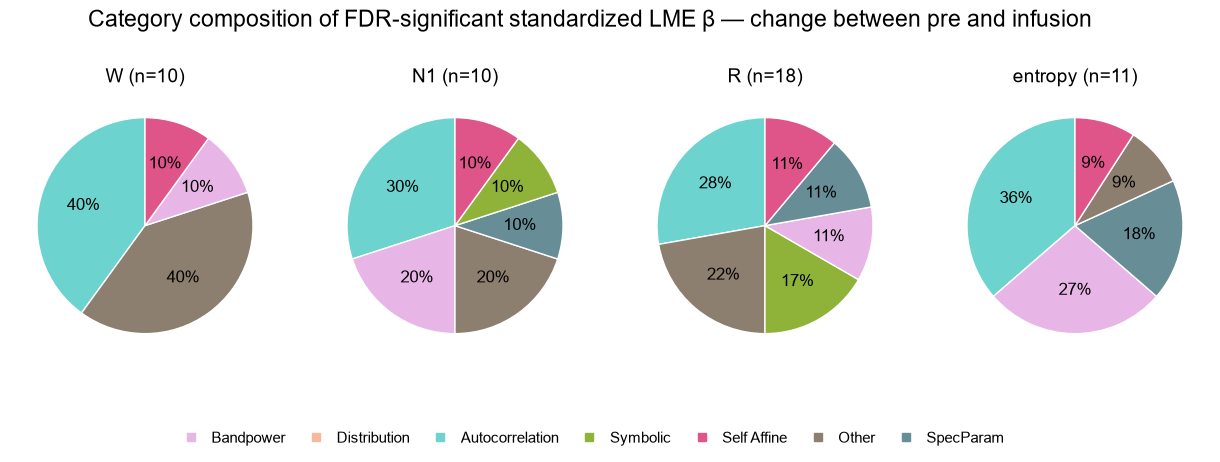

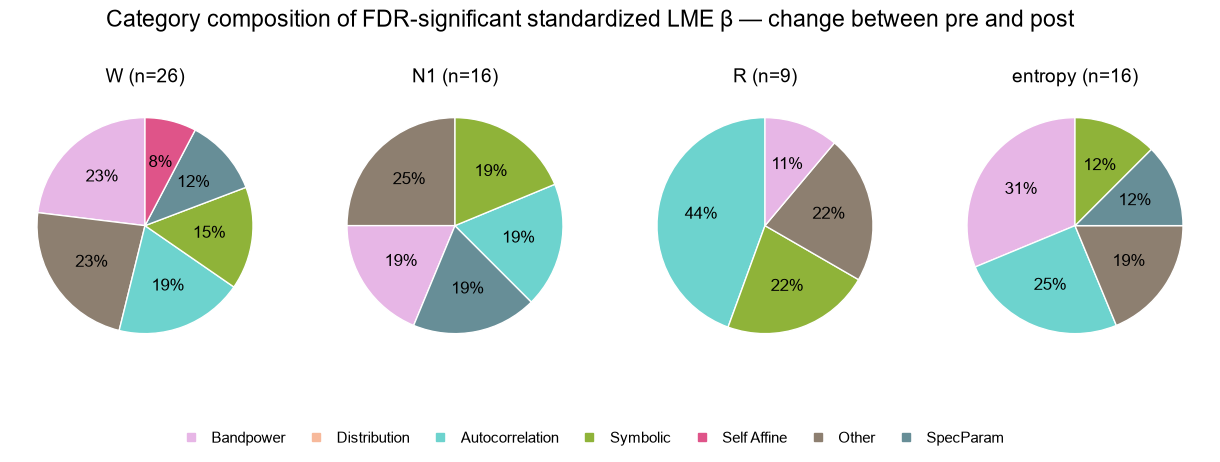

In [33]:
SIGNIFICANCE_ALPHA = 0.05
for contrast in ('after', 'late'):
    contrast_data = lme_source.loc[lme_source['contrast'].eq(contrast)]
    figure, axes = plt.subplots(1, len(target_order), figsize=(16, 4.5), squeeze=False)
    for col, response in enumerate(target_order):
        axis = axes[0, col]
        stage_data = contrast_data.loc[contrast_data['response'].eq(response)]
        selected = stage_data.loc[stage_data['q_fdr'].lt(SIGNIFICANCE_ALPHA)]
        if selected.empty:
            axis.text(.5, .5, 'No significant\nfeatures', ha='center', va='center',
                      transform=axis.transAxes, fontsize=10, color='#6b7280')
            axis.set_axis_off()
            axis.set_title(response)
            continue
        counts = selected['feature'].map(FEATURE_CATEGORY).value_counts()
        colors = [CATEGORY_COLORS[category] for category in counts.index]
        axis.pie(counts.to_numpy(), colors=colors, wedgeprops={"linewidth": 1, "edgecolor": "white"}, autopct='%1.0f%%', startangle=90, textprops={'fontsize': 12})
        axis.set_title(f'{response} (n={len(selected)})')
    figure.suptitle(
        f'Category composition of FDR-significant standardized LME β '
        f'— change between pre and {CONTRAST_PHASE_WORD[contrast]}'
    )
    category_handles = [plt.Line2D([0], [0], marker='s', linestyle='', color=color, label=category) for category, color in CATEGORY_COLORS.items()]
    figure.legend(handles=category_handles, loc='lower center', bbox_to_anchor=(.5, -.02), ncol=len(category_handles), frameon=False, columnspacing=1.0, handletextpad=.35)
    figure.subplots_adjust(bottom=.2, top=.8, wspace=0)
    save_figure(figure, FIGURES_DIR / f'07_category_composition_significant_{contrast}', formats=('png', 'svg', 'pdf')); plt.show()

In [34]:
# Data needed to reproduce the category-composition pie charts without recomputing anything
# (same style as the CSV exports in 02_hypnodensity_analysis.ipynb / 06_figure2.ipynb): one row
# per (contrast, response, feature) that was FDR-significant and therefore counted in a pie slice.
pie_chart_plot_data = lme_source.loc[
    lme_source['q_fdr'].lt(SIGNIFICANCE_ALPHA), ['contrast', 'response', 'feature', 'estimate_std', 'q_fdr']
].copy()
pie_chart_plot_data['category'] = pie_chart_plot_data['feature'].map(FEATURE_CATEGORY)
pie_chart_plot_data_path = TABLES_DIR / 'category_composition_significant_plot_data.csv'
save_table(pie_chart_plot_data, pie_chart_plot_data_path)
display(f'Saved category composition figure data to {pie_chart_plot_data_path}')

'Saved category composition figure data to c:\\Users\\Bruna\\Documents\\Cogmaster\\M1\\S2\\dmt_hypnodensities\\outputs\\feature_hypnodensity_correlations_000s_gssc_v2\\tables\\category_composition_significant_plot_data.csv'

In [ ]:
def plot_delta_lme_composite(
    beta_matrix_csv=None,
    category_composition_csv=None,
    contrast='after',
    save_path=None,
):
    """Rebuild the standardized LME matrix (A) and category pies (B) from exported CSVs."""
    beta_matrix_csv = beta_matrix_csv or TABLES_DIR / 'beta_matrix_plot_data.csv'
    category_composition_csv = category_composition_csv or TABLES_DIR / 'category_composition_significant_plot_data.csv'

    matrix_data = pd.read_csv(beta_matrix_csv)
    pie_data = pd.read_csv(category_composition_csv)
    required_matrix = {'contrast', 'response', 'feature', 'estimate_std', 'q_fdr', 'stars', 'beta_limit'}
    required_pie = {'contrast', 'response', 'feature', 'category'}
    missing_matrix = required_matrix - set(matrix_data.columns)
    missing_pie = required_pie - set(pie_data.columns)
    if missing_matrix or missing_pie:
        raise ValueError(
            f'Missing matrix columns: {sorted(missing_matrix)}; '
            f'pie columns: {sorted(missing_pie)}'
        )
    if contrast not in ('after', 'late'):
        raise ValueError("contrast must be 'after' or 'late'")

    matrix_data = matrix_data.loc[matrix_data['contrast'].eq(contrast)].copy()
    pie_data = pie_data.loc[pie_data['contrast'].eq(contrast)].copy()
    if matrix_data.empty:
        raise ValueError(f'No matrix data for contrast {contrast!r} in {beta_matrix_csv}.')

    phase_word = {'after': 'infusion', 'late': 'post'}[contrast]
    responses = list(target_order)
    feature_order = (
        matrix_data.loc[matrix_data['response'].eq('W')]
        .sort_values('estimate_std', ascending=False)['feature'].tolist()
    )
    if not feature_order:
        raise ValueError(f'No W response rows for contrast {contrast!r} in {beta_matrix_csv}.')
    matrix = matrix_data.pivot(index='response', columns='feature', values='estimate_std').reindex(
        index=responses, columns=feature_order
    )
    stars = matrix_data.pivot(index='response', columns='feature', values='stars').reindex(
        index=responses, columns=feature_order
    ).fillna('')
    beta_limits = matrix_data['beta_limit'].dropna()
    if beta_limits.empty:
        raise ValueError(f'No finite beta_limit value found in {beta_matrix_csv}.')
    beta_limit_local = float(beta_limits.iloc[0])

    def label_panel(axis, letter, title):
        axis.set_title(f"{letter} {title}", loc='left', pad=10, fontweight='bold')

    figure = plt.figure(figsize=(16, 11))
    outer = figure.add_gridspec(2, 1, height_ratios=(1.15, 1), hspace=0.8)

    # --- Panel A: standardized LME coefficient matrix ---
    axis_a = figure.add_subplot(outer[0])
    matrix_values = matrix.to_numpy(float)
    image = axis_a.imshow(
        matrix_values, vmin=-beta_limit_local, vmax=beta_limit_local,
        cmap='coolwarm', aspect='auto',
    )
    axis_a.set_xticks(
        np.arange(len(feature_order)),
        [FEATURE_LABEL.get(feature, feature) for feature in feature_order],
        rotation=75, ha='right',
    )
    axis_a.set_yticks(np.arange(len(responses)), responses)
    axis_a.set_xlabel('Features (ordered by standardized W LME coefficient \u03b2)')
    axis_a.set_xticks(np.arange(-.5, len(feature_order), 1), minor=True)
    axis_a.set_yticks(np.arange(-.5, len(responses), 1), minor=True)
    axis_a.grid(False, which='major')
    axis_a.grid(which='minor', color='white', linewidth=1.2)
    axis_a.tick_params(which='minor', bottom=False, left=False)
    for label, feature in zip(axis_a.get_xticklabels(), feature_order):
        label.set_color(CATEGORY_COLORS[FEATURE_CATEGORY[feature]])
    for row, response in enumerate(responses):
        for col, feature in enumerate(feature_order):
            axis_a.text(
                col, row, stars.loc[response, feature], ha='center', va='center',
                color='black',
            )
    clipped = np.isfinite(matrix_values).any() and np.nanmax(np.abs(matrix_values)) > beta_limit_local
    figure.colorbar(
        image, ax=axis_a,
        label='Standardized LME interaction coefficient \u03b2\n(\u03b2 / SD(\u0394response))',
        extend='both' if clipped else 'neither',
    )
    #category_legend(axis_a)
    title_a = f'Standardized LME coefficient matrix \u2014 change between pre and {phase_word}'
    label_panel(axis_a, 'A', title_a)

    # --- Panel B: category composition of significant coefficients ---
    panel_b_layout = outer[1].subgridspec(2, 1, height_ratios=(.12, 1.3), hspace=0)
    panel_b = figure.add_subplot(panel_b_layout[0])
    panel_b.set_axis_off()
    # panel_b.set_title(
    #     f'Category composition of FDR-significant standardized LME \u03b2 \u2014 change between pre and {phase_word}',
    #     loc='left', pad=10,
    # )
    title_b = f'Category composition of FDR-significant standardized LME \u03b2 \u2014 change between pre and {phase_word}'
    label_panel(panel_b, 'B', title_b)
    pie_grid = panel_b_layout[1].subgridspec(1, len(responses), wspace=0.02)
    pie_axes = [figure.add_subplot(pie_grid[0, col]) for col in range(len(responses))]
    for axis_b, response in zip(pie_axes, responses):
        selected = pie_data.loc[pie_data['response'].eq(response)]
        counts = selected['category'].value_counts().reindex(CATEGORY_COLORS.keys(), fill_value=0)
        counts = counts.loc[counts.gt(0)]
        if counts.empty:
            axis_b.text(
                .5, .5, 'No significant\nfeatures', ha='center', va='center',
                transform=axis_b.transAxes, color='#6b7280',
            )
            axis_b.set_axis_off()
            axis_b.set_title(response)
        else:
            axis_b.pie(
                counts.to_numpy(), colors=[CATEGORY_COLORS[category] for category in counts.index],
                wedgeprops={'linewidth': 1, 'edgecolor': 'white'}, autopct='%1.0f%%',
                startangle=90, radius=1.15
            )
            axis_b.set_title(f'{response} (n={int(counts.sum())})')

    category_handles = [
        plt.Line2D([0], [0], marker='s', linestyle='', color=color, label=category)
        for category, color in CATEGORY_COLORS.items()
    ]
    figure.legend(
        handles=category_handles, loc='lower center', bbox_to_anchor=(.5, .015),
        ncol=len(category_handles), frameon=False,
    )
    if save_path is not None:
        save_figure(figure, save_path, formats=('png', 'svg', 'pdf'))
    return figure

# Recreate the pre-to-infusion composite directly from the exported tables in TABLES_DIR.
plot_delta_lme_composite(
    contrast='after',
    save_path=FIGURES_DIR / '08_delta_lme_composite_after',
)
plt.show()
